# Stage 3: SQL analysis (SQLite)
Credit risk teams live in SQL: portfolio monitoring, vintage reports and ad-hoc questions from the
Chief Risk Officer are usually answered straight from the warehouse. This stage:
1. Loads the raw CSVs into a SQLite database (`database/home_credit.db`) with indexes on the join keys.
2. Creates reusable views (`sql/01_create_views.sql`).
3. Runs the analysis queries in `sql/02_analysis_queries.sql`: joins, aggregations, CTEs and window functions.

Each query answers one business question. Results are saved to `reports/sql/` for the README and dashboard.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px

from credit_risk.config import get_paths, load_config
from credit_risk.database import build_database, get_connection, list_tables, load_named_queries, run_query, run_sql_script
from credit_risk.viz import COLORS, savefig, set_style

cfg = load_config()
paths = get_paths(cfg)
set_style()

## 1. Build the database
Loading streams each CSV in chunks of 250k rows, so the 27M-row `bureau_balance` never has to fit in memory.
On the full data the first build takes roughly 5-10 minutes. After that, set `REBUILD = False`.

In [2]:
REBUILD = not paths["database"].exists()

if REBUILD:
    load_summary = build_database(cfg)
    display(load_summary)

conn = get_connection(paths["database"])
run_sql_script(paths["sql_dir"] / "01_create_views.sql", conn)
print("Tables & views:", list_tables(conn), "| views:", [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='view'")])

  loaded application_train             307,511 rows in   11.0s
  loaded application_test               48,744 rows in    1.9s
  loaded bureau                      1,716,428 rows in    8.7s
  loaded bureau_balance             27,299,925 rows in   44.6s
  loaded previous_application        1,670,214 rows in   21.4s
  loaded pos_cash_balance           10,001,358 rows in   55.6s
  loaded installments_payments      13,605,401 rows in   72.5s
  loaded credit_card_balance         3,840,312 rows in   26.9s


,table,rows_loaded,seconds
0,application_train,307511,11.0
1,application_test,48744,1.9
2,bureau,1716428,8.7
3,bureau_balance,27299925,44.6
4,previous_application,1670214,21.4
5,pos_cash_balance,10001358,55.6
6,installments_payments,13605401,72.5
7,credit_card_balance,3840312,26.9


Tables & views: ['application_test', 'application_train', 'bureau', 'bureau_balance', 'credit_card_balance', 'installments_payments', 'pos_cash_balance', 'previous_application'] | views: ['v_applications', 'v_bureau_summary', 'v_previous_summary']


## 2. Run the analysis queries

In [3]:
queries = load_named_queries(paths["sql_dir"] / "02_analysis_queries.sql")
results = {}
out_dir = paths["reports"] / "sql"
out_dir.mkdir(parents=True, exist_ok=True)

for name, q in queries.items():
    df = run_query(q["sql"], conn)
    results[name] = df
    df.to_csv(out_dir / f"{name}.csv", index=False)
print(f"Ran {len(results)} queries -> {out_dir.relative_to(ROOT)}")


def show(name):
    print(f"Q: {queries[name]['question']}")
    display(results[name])

Ran 19 queries -> reports\sql


### 2.1 Portfolio overview

In [4]:
show("table_row_counts")
show("portfolio_default_rate")

Q: How big is each table? (data-volume sanity check)


,table_name,row_count
0,application_train,307511
1,bureau,1716428
2,previous_application,1670214
3,installments_payments,13605401
4,pos_cash_balance,10001358
5,credit_card_balance,3840312


Q: What is the overall default rate and the exposure at risk?


,applicants,defaults,default_rate_pct,total_credit_mn,credit_of_defaulters_mn,exposure_default_pct
0,307511,24825,8.07,184207.1,13846.9,7.52


### 2.2 Who defaults? Customer segments
`SUM(COUNT(*)) OVER ()` puts each segment's share of the portfolio next to its risk. A high-risk segment that is 0.01%
of applicants matters far less than a moderately risky one that is 50%.

In [5]:
show("default_by_contract_type")
show("default_by_income_type")
show("default_by_education_ranked")

Q: Do cash loans and revolving loans carry different risk?


,NAME_CONTRACT_TYPE,applicants,portfolio_share_pct,default_rate_pct,avg_credit
0,Cash loans,278232,90.5,8.35,627966.0
1,Revolving loans,29279,9.5,5.48,324018.0


Q: Which income types are riskiest, and how much of the book do they represent?


,NAME_INCOME_TYPE,applicants,portfolio_share_pct,default_rate_pct,vs_portfolio_pp
0,Unemployed,22,0.01,36.36,28.29
1,Working,158774,51.64,9.59,1.52
2,Commercial associate,71617,23.29,7.48,-0.59
3,State servant,21703,7.06,5.75,-2.32
4,Pensioner,55362,18.01,5.39,-2.69


Q: Rank education levels by default rate (window function RANK).


,NAME_EDUCATION_TYPE,applicants,default_rate_pct,risk_rank
0,Lower secondary,3816,10.93,1
1,Secondary / secondary special,218391,8.94,2
2,Incomplete higher,10277,8.48,3
3,Higher education,74863,5.36,4
4,Academic degree,164,1.83,5


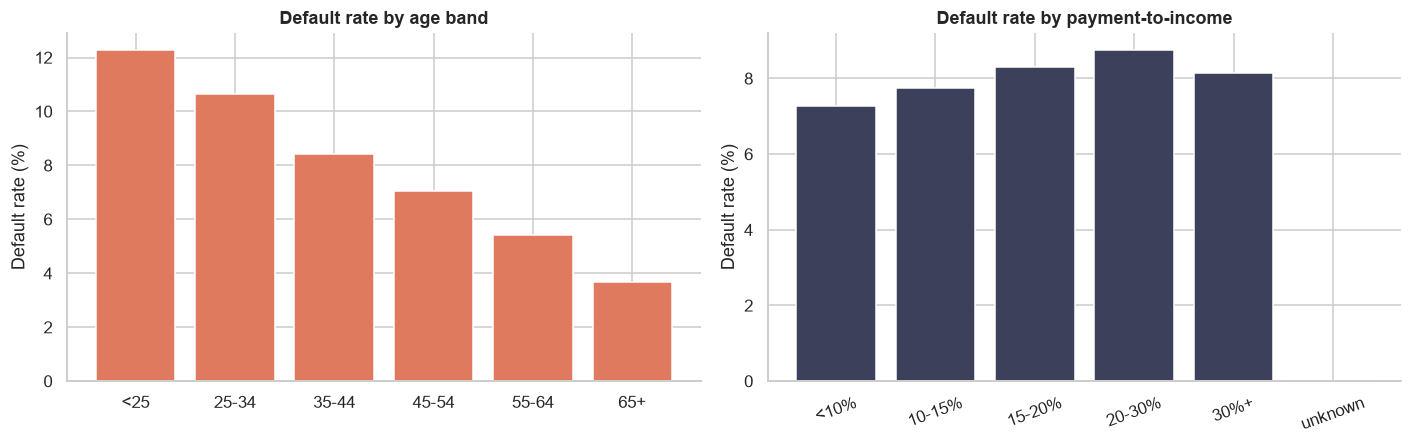

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
d = results["default_by_age_band"]
axes[0].bar(d["age_band"].str[3:], d["default_rate_pct"], color=COLORS["bad"])
axes[0].set(title="Default rate by age band", ylabel="Default rate (%)")
d = results["default_by_affordability"]
axes[1].bar(d["payment_to_income_band"].str[3:], d["default_rate_pct"], color=COLORS["neutral"])
axes[1].set(title="Default rate by payment-to-income", ylabel="Default rate (%)")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
savefig(fig, "sql_age_affordability")
plt.show()

In [7]:
show("default_by_income_quintile")

Q: Is income alone a good risk separator? (NTILE quintiles)


,income_quintile,min_income,max_income,applicants,default_rate_pct
0,1,25650.0,99000.0,61503,8.19
1,2,99000.0,135000.0,61502,8.75
2,3,135000.0,162000.0,61502,8.48
3,4,162000.0,225000.0,61502,8.15
4,5,225000.0,117000000.0,61502,6.79


### 2.3 One external score already ranks risk well (NTILE + running total)
`cum_defaults_captured_pct` answers a classic business question: *if we declined the lowest-scoring X% of applicants,
what share of defaulters would we avoid?* Our model must beat this simple single-score rule.

Q: How well does a single external score rank risk? Cumulative share of defaults captured (running SUM window).


,decile,min_score,max_score,applicants,default_rate_pct,cum_defaults_captured_pct
0,1,0.000,0.216,30686,18.35,22.7
1,2,0.216,0.340,30685,12.08,37.7
2,3,0.340,0.440,30685,9.96,50.0
3,4,0.440,0.512,30685,8.36,60.4
4,5,0.512,0.566,30685,7.42,69.6
5,6,0.566,0.608,30685,6.65,77.8
6,7,0.608,0.646,30685,5.85,85.1
7,8,0.646,0.682,30685,4.89,91.1
8,9,0.682,0.722,30685,4.20,96.3
9,10,0.722,0.855,30685,2.97,100.0


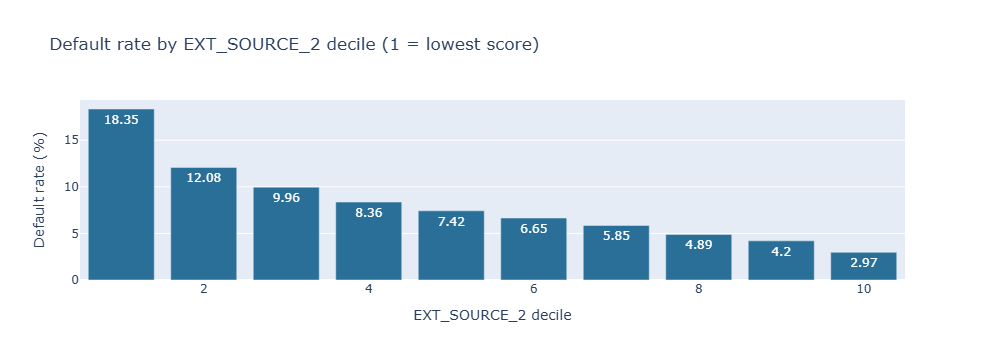

In [8]:
show("ext_source_decile_gains")
d = results["ext_source_decile_gains"]
fig = px.bar(d, x="decile", y="default_rate_pct", text="default_rate_pct",
             title="Default rate by EXT_SOURCE_2 decile (1 = lowest score)",
             labels={"decile": "EXT_SOURCE_2 decile", "default_rate_pct": "Default rate (%)"})
fig.update_traces(marker_color=COLORS["good"])
fig.write_html(paths["figures"] / "sql_ext_source_deciles.html")
fig.show()

### 2.4 Credit history at other lenders (bureau joins)

In [9]:
show("bureau_active_loans_vs_default")
show("bureau_debt_utilisation_vs_default")
show("worst_bureau_delinquency")

Q: Do clients with more active loans at other lenders default more? (CTE + LEFT JOIN)


,active_bureau_loans,applicants,default_rate_pct
0,0. no bureau record,44020,10.12
1,1. none active,46341,5.66
2,2. 1-2 active,132486,7.25
3,3. 3-4 active,60052,8.62
4,4. 5+ active,24612,12.05


Q: Does leverage on existing credit (debt / credit on active lines) predict default?


,debt_utilisation_band,applicants,default_rate_pct
0,0. no active credit,93440,7.79
1,1. <25%,56648,6.15
2,2. 25-50%,35184,6.71
3,3. 50-75%,51052,7.59
4,4. 75%+,71187,11.00


Q: Worst monthly delinquency status ever reported to the bureau (3-table join: application -> bureau -> bureau_balance).


,worst_bureau_status,applicants,default_rate_pct
0,0. never past due,61179,7.22
1,1. 1-30 DPD,24686,10.06
2,2. 31-60 DPD,2961,8.75
3,3. 60+ DPD / written off,3405,10.28
4,no monthly history,215280,8.04


### 2.5 Behaviour with Home Credit (previous applications, instalments, cards)
Past repayment behaviour is usually the single strongest predictor of future repayment.

In [10]:
show("previous_refusals_vs_default")
show("last_previous_application_status")
show("payment_delay_vs_default")
show("credit_card_utilisation_vs_default")
show("application_frequency_vs_default")

Q: Are clients previously refused by Home Credit riskier today?


,refusal_history,applicants,default_rate_pct
0,0. new client,16454,5.96
1,1. never refused,190763,7.07
2,2. refused once,46534,8.83
3,3. refused 2-3x,34598,10.65
4,4. refused 4x+,19162,13.34


Q: What did the client's MOST RECENT previous application look like? (ROW_NUMBER to pick latest)


,last_previous_status,applicants,default_rate_pct,avg_days_since_decision
0,Refused,32324,12.50,416.0
1,Unused offer,5552,8.72,435.0
2,Canceled,74537,8.25,161.0
3,Approved,178644,7.37,627.0
4,No previous application,16454,5.96,NaN


Q: Payment behaviour on past loans: does the share of late instalments predict default? (multi-step CTE)


,lateness_band,applicants,avg_worst_delay_days,default_rate_pct
0,0. no instalment history,15876,NaN,5.98
1,1. never late,136636,0.0,6.80
2,2. <5% late,38976,19.5,6.92
3,3. 5-15% late,60022,31.3,9.14
4,4. 15-30% late,37761,41.5,10.50
5,5. 30%+ late,18240,63.2,13.34


Q: Latest credit-card utilisation before the application (ROW_NUMBER on monthly snapshots).


,utilisation_band,applicants,default_rate_pct
0,0. no card,220606,7.84
1,1. no limit,21208,7.25
2,2. <30%,39348,5.73
3,3. 30-70%,5048,7.71
4,4. 70-100%,12839,12.84
5,5. over limit,8462,20.14


Q: Do clients who apply for credit in quick succession default more? (LAG between consecutive applications)


,application_frequency,applicants,default_rate_pct
0,0. fewer than 2 applications,68987,7.80
1,1. < 1 month apart,9522,11.49
2,2. 1-6 months apart,60749,10.86
3,3. 6-12 months apart,75330,7.71
4,4. > 1 year apart,92923,6.40


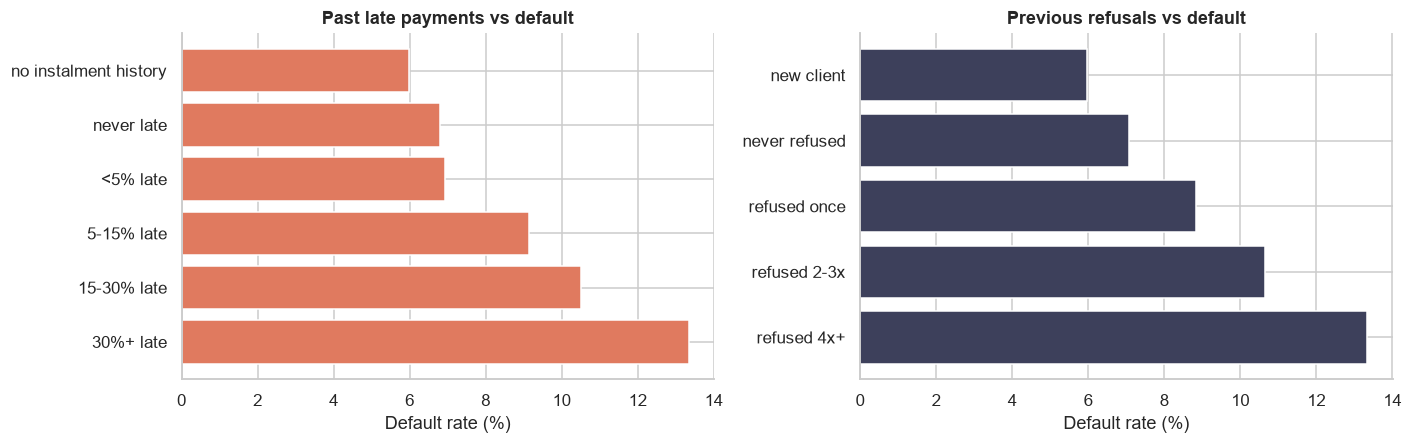

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
d = results["payment_delay_vs_default"]
axes[0].barh(d["lateness_band"].str[3:], d["default_rate_pct"], color=COLORS["bad"])
axes[0].invert_yaxis()
axes[0].set(title="Past late payments vs default", xlabel="Default rate (%)")
d = results["previous_refusals_vs_default"]
axes[1].barh(d["refusal_history"].str[3:], d["default_rate_pct"], color=COLORS["neutral"])
axes[1].invert_yaxis()
axes[1].set(title="Previous refusals vs default", xlabel="Default rate (%)")
fig.tight_layout()
savefig(fig, "sql_behaviour")
plt.show()

### 2.6 Concentration and segment heat-map

In [12]:
show("segment_matrix_region_education")
show("top_occupations_by_exposure")

Q: Risk heat-map: region rating x education (conditional aggregation pivot).


,region_rating,higher_edu_pct,incomplete_higher_pct,secondary_pct,lower_secondary_pct,applicants
0,1,3.37,5.93,5.60,7.60,34167
1,2,5.34,8.10,8.69,10.40,229484
2,3,7.87,13.46,12.36,14.29,43860


Q: Which occupations hold the most credit exposure, and how risky are they? (running share of exposure)


,occupation,applicants,exposure_mn,default_rate_pct,cum_exposure_pct,risk_rank
0,Unknown,96391,55360.2,6.51,30.1,13
1,Laborers,55186,31490.1,10.58,47.1,5
2,Sales staff,32102,18081.7,9.63,57.0,7
3,Core staff,27570,17237.4,6.30,66.3,16
4,Managers,21371,16564.5,6.21,75.3,17
5,Drivers,18603,11391.2,11.33,81.5,2
6,High skill tech staff,11380,7316.3,6.16,85.5,18
7,Accountants,9813,6964.8,4.83,89.3,19
8,Medicine staff,8537,5185.6,6.70,92.1,11
9,Security staff,6721,3744.1,10.74,94.1,4


## 3. Business findings (fill in with your numbers from the full data)
On the full Kaggle data you should see patterns like these. Replace them with your own figures once you have run the notebook:

| Theme | Typical finding | Business implication |
|---|---|---|
| Portfolio | ~8% of applicants have payment difficulties | Accuracy is meaningless: approving everyone is 92% "accurate" |
| Product | Cash loans default more than revolving loans | Price or limit cash loans differently |
| Income type | Unemployed / maternity-leave applicants are far riskier; pensioners and state servants safer | Income stability matters more than income level |
| Education | Clear monotonic gradient: lower secondary riskiest, academic degree safest | Useful but must be checked for fair-lending proxies |
| Age | Default rate falls steadily with age | Age is predictive, and also legally sensitive (Stage 12) |
| External scores | The bottom EXT_SOURCE decile defaults several times more often than the top | Strong baseline to beat; our model combines it with behaviour |
| Past behaviour | Clients with many late instalments or previous refusals default far more | Aggregating history (Stage 6) is where the lift comes from |

These SQL findings become hypotheses for EDA (Stage 5) and features (Stage 6).

In [13]:
conn.close()